# Paw speed against wheel speed, per paw state (supplementary)

One panel per paw state (uniform numbering, vigor order, as fig_segmentation). Each dot is one video frame (60 Hz) assigned to that state: wheel speed on x, the speed of each paw on y, **left paw and right paw in their palette colours** (`ps.PAW_LEFT`, `ps.PAW_RIGHT`).

* **Paw speed** = the norm of the paw's (x, y) velocity, velocity = diff(position / camera resolution) × 60 per axis, the velocity the paw wavelets are computed from (left camera resolution 2, right 1). **Normalised per session** by dividing by the session's SD of paw speed (not z-scored, so zero speed stays at zero).
* **Wheel speed** = |`avg_wheel_vel`| from the states files, in its own units (not normalised).
* Paw state = the paw part of `most_likely_states`, mapped to the uniform numbering with `ps.paw_codes`.
* **Sampling**: every session counts equally — `N_PER_SESSION` random frames per session and state (fewer if the session has fewer), so long or very active sessions do not dominate a panel. Sessions = those in fig_segmentation's syllable file.
* r in each panel: Pearson correlation of each paw's speed with wheel speed over the plotted frames.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from joblib import Parallel, delayed
from datetime import date

FIGDIR = pathlib.Path.cwd().resolve()
while not (FIGDIR / 'fig_layout.py').exists() and FIGDIR != FIGDIR.parent:
    FIGDIR = FIGDIR / 'figure_generation' if (FIGDIR / 'figure_generation').exists() else FIGDIR.parent
PI = FIGDIR.parent
for p in [str(PI), str(FIGDIR)]:
    if p not in sys.path:
        sys.path.insert(0, p)
import paper_style as ps
import fig_layout as fl
ps.use('paper')
ps.use_paw_states('uniform')
FIG = 'fig_paw_wheel_velocity'

SYLLABLE_FILE = PI / 'data' / '8_k_10_bin_syllables_02-10-2026'   # fig_segmentation's; only picks the sessions
STATES_FILES_DIR = PI / 'data' / 'states_files'
RES = {'l': 2, 'r': 1}          # camera resolution factor: left / right camera (as 3.1.1_paw_wavelets)
FS = 60
N_PER_SESSION = 20              # frames per session and paw state
SEED = 0
N_COLS = 4
LIM_PCT = 95         # axis tops: this percentile of the plotted speeds (the long tails are clipped)
PAD = 0.04           # axes start this fraction of their range below 0, so pile-ups ON the zero lines show
DOT_SIZE, DOT_ALPHA = 4.0, 0.10

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Frames: wheel velocity, z-scored paw velocity, paw state

In [2]:
_seq = pd.read_parquet(SYLLABLE_FILE, columns=['sample', 'mouse_name'])
SESSIONS = (_seq.assign(session=_seq['sample'].str[:36])[['session', 'mouse_name']].drop_duplicates()
            .itertuples(index=False, name=None))
SESSIONS = list(SESSIONS)

def session_frames(eid, mouse, seed):
    ps.use_paw_states('uniform')   # joblib workers import paper_style afresh, i.e. as 'production' (paw_codes = identity)
    d = pd.read_parquet(STATES_FILES_DIR / f'8_states_file_{eid}_{mouse}',
                        columns=['Bin', 'avg_wheel_vel', 'l_paw_x', 'l_paw_y', 'r_paw_x', 'r_paw_y', 'most_likely_states']
                        ).sort_values('Bin').reset_index(drop=True)
    out = pd.DataFrame({'wheel': np.abs(d['avg_wheel_vel'].to_numpy(float))})
    for p in ('l', 'r'):
        vx, vy = (np.r_[np.nan, np.diff(d[f'{p}_paw_{a}'].to_numpy(float) / RES[p]) * FS] for a in 'xy')   # frame t: t-1 -> t
        v = np.hypot(vx, vy)
        out[p] = v / np.nanstd(v)
    out['state'], _, _ = ps.decode_syllables(ps.paw_codes(d['most_likely_states'].to_numpy(float)))
    out = out.dropna()            # frames with no state or no tracking are dropped, not interpolated
    rng = np.random.default_rng(seed)
    keep = [rng.choice(ix, min(N_PER_SESSION, len(ix)), replace=False) for ix in out.groupby('state').indices.values()]
    return out.iloc[np.concatenate(keep)].assign(session=eid, mouse_name=mouse)

FR = pd.concat(Parallel(n_jobs=8)(delayed(session_frames)(e, m, SEED + i) for i, (e, m) in enumerate(SESSIONS)),
               ignore_index=True)
FR['state'] = FR['state'].astype(int)
print(f"{len(SESSIONS)} sessions, {FR['mouse_name'].nunique()} mice, {len(FR):,} frames")
print(FR.groupby('state').size().rename('frames').to_frame()
      .join(FR.groupby('state')[['l', 'r']].apply(lambda g: g.abs().median()).add_prefix('median speed ')).round(2).T)

332 sessions, 101 mice, 53,112 frames
state                 0        1        2        3        4        5        6  \
frames          6640.00  6640.00  6640.00  6640.00  6640.00  6640.00  6640.00   
median speed l     0.01     0.03     0.48     0.55     0.22     1.99     1.22   
median speed r     0.02     0.03     0.21     0.87     0.18     0.69     2.01   

state                 7  
frames          6632.00  
median speed l     2.07  
median speed r     1.57  


## The figure

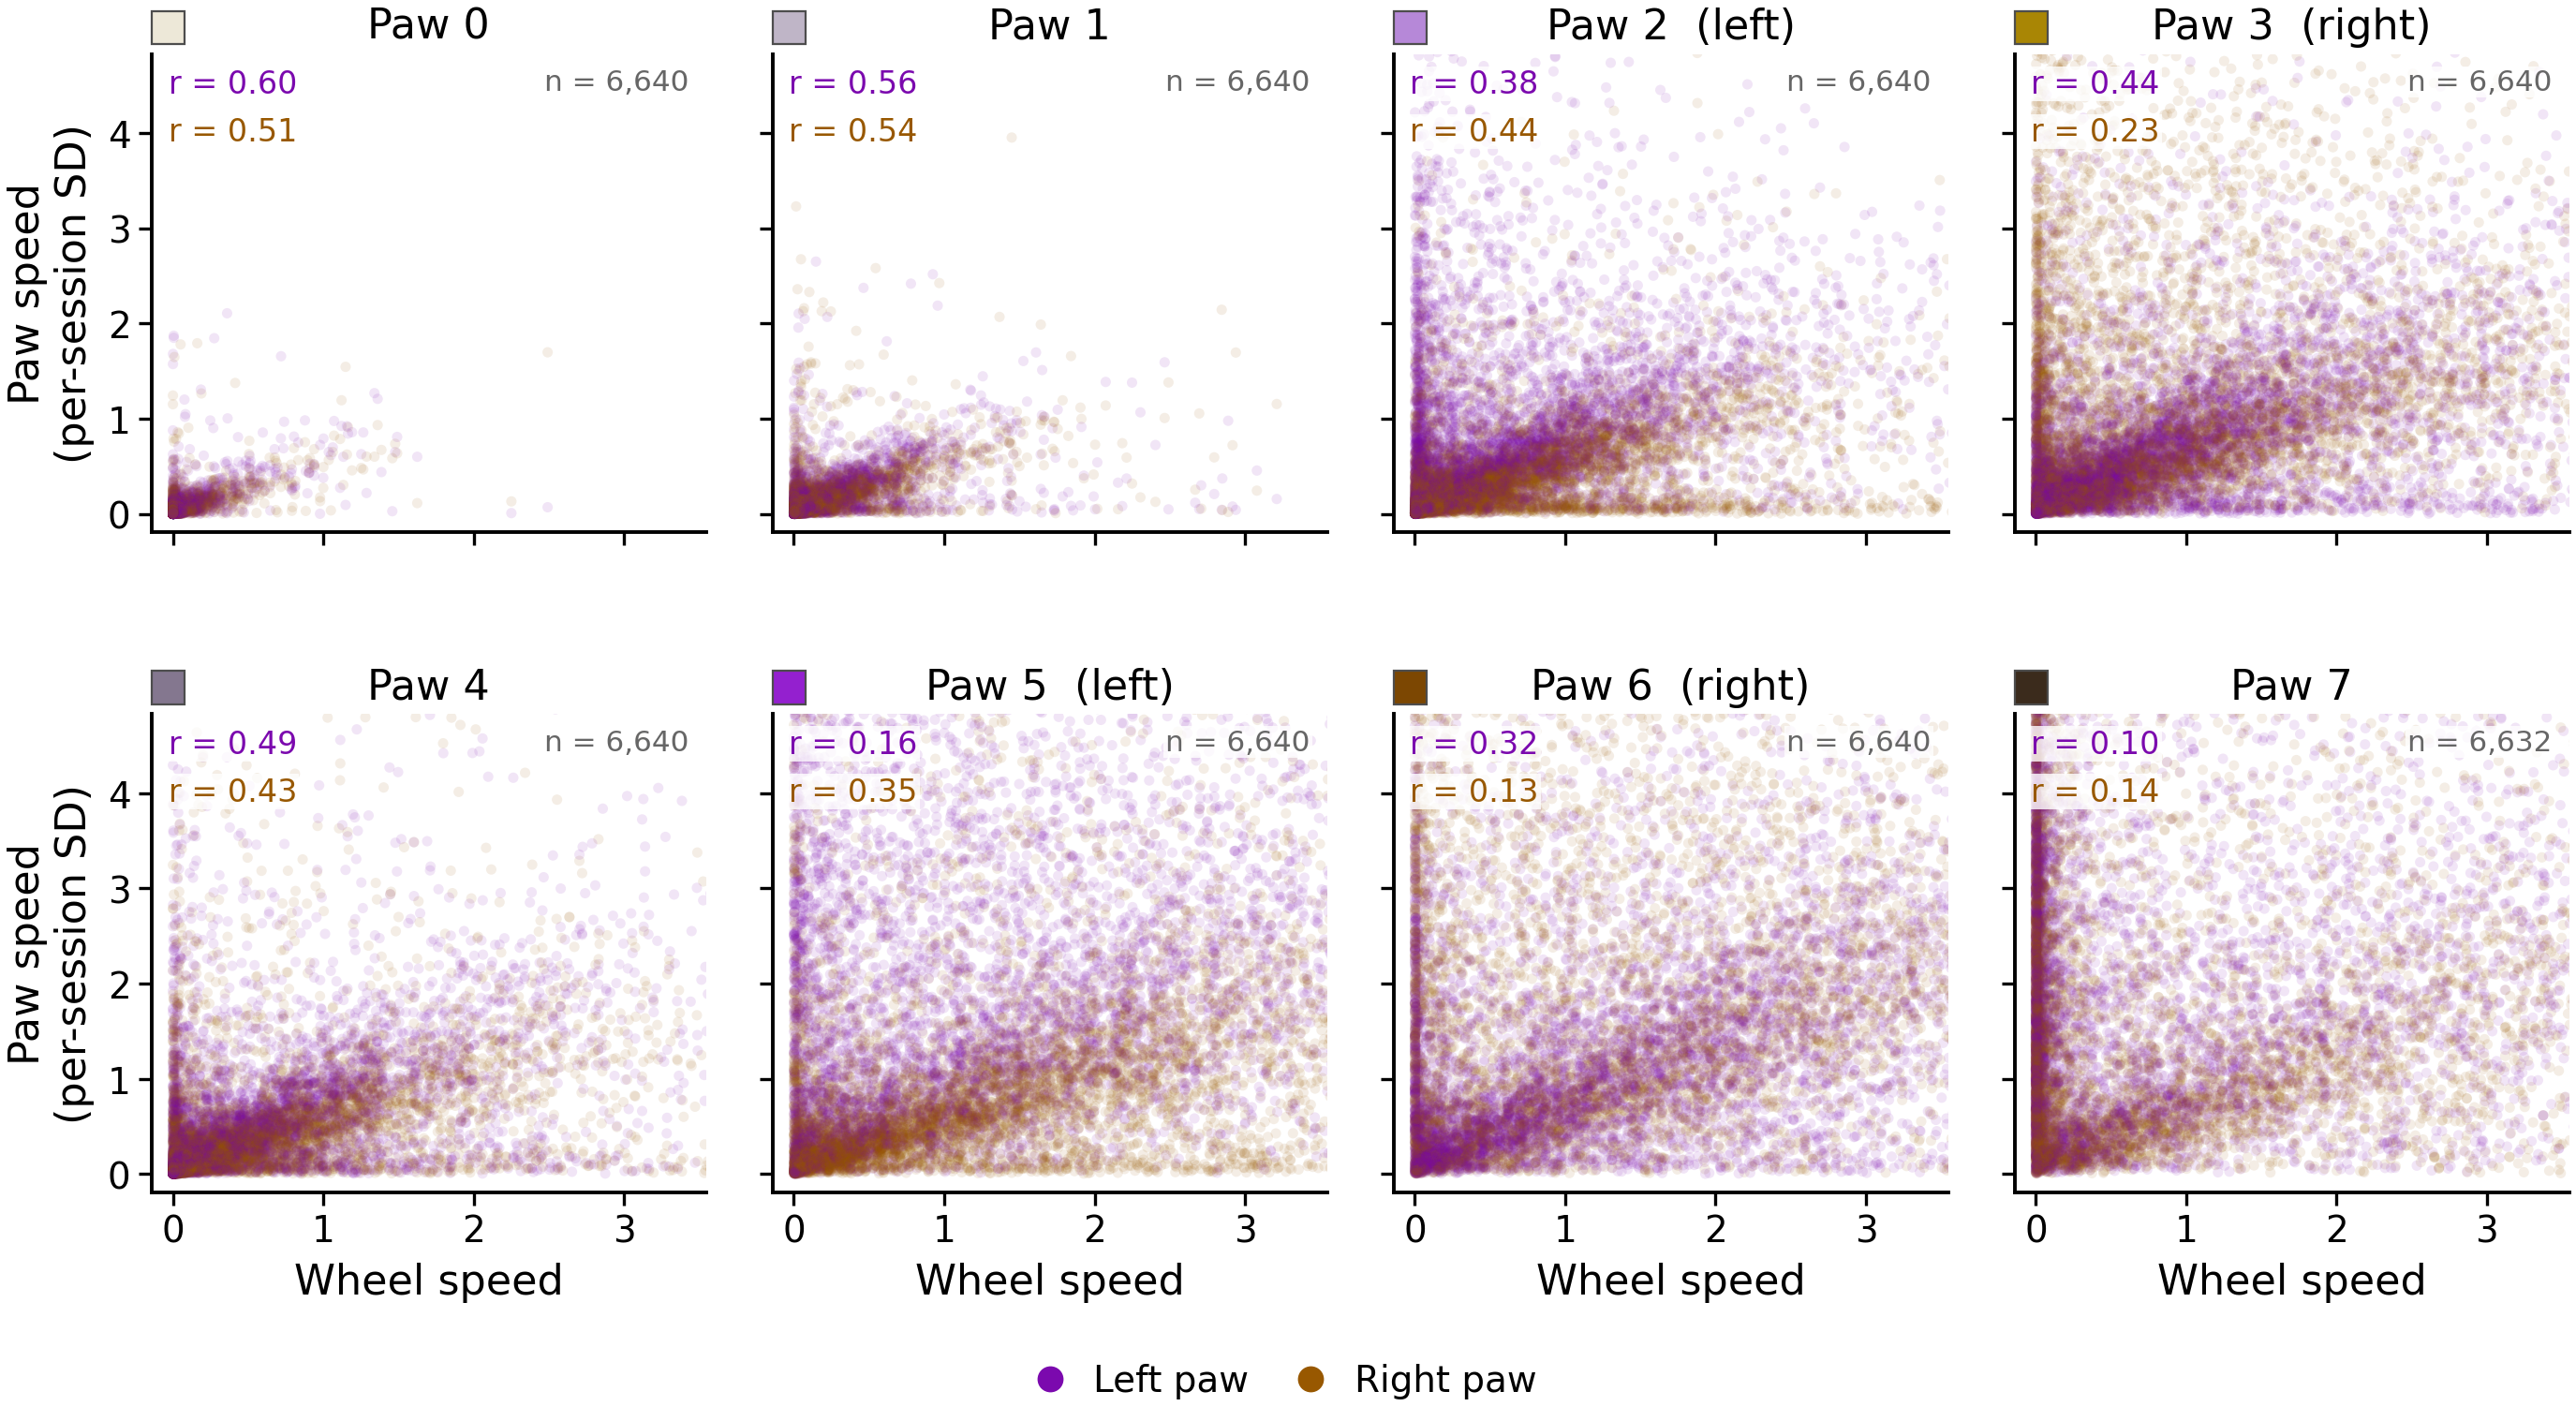

wrote figure_generation/figures/fig_paw_wheel_velocity_02-11-2026.svg


wrote figure_generation/figures/fig_paw_wheel_velocity.pdf


wrote figure_generation/figures/fig_paw_wheel_velocity.png


In [3]:
ORDER = list(ps.PAW_VIGOR_ORDER)
XL = np.nanpercentile(FR['wheel'], LIM_PCT)
YL = np.nanpercentile(FR[['l', 'r']].to_numpy(), LIM_PCT)
PAWS = [('l', 'Left paw', ps.PAW_LEFT), ('r', 'Right paw', ps.PAW_RIGHT)]

n_rows = int(np.ceil(len(ORDER) / N_COLS))
fig = plt.figure(figsize=(fl.FIG_WIDTH, 1.75 * n_rows + 0.35))
G = fig.add_gridspec(n_rows, N_COLS, wspace=0.12, hspace=0.38, left=0.075, right=0.985, top=0.95,
                     bottom=0.35 / (1.75 * n_rows + 0.35) + 0.07)
rng = np.random.default_rng(SEED)
axes = []
for i, s in enumerate(ORDER):
    r_, c_ = divmod(i, N_COLS)
    ax = fig.add_subplot(G[r_, c_], sharex=axes[0] if axes else None, sharey=axes[0] if axes else None); axes.append(ax)
    d = FR[FR['state'] == s]
    # both paws in one shuffled draw order, so neither colour is systematically painted over the other
    x = np.r_[d['wheel'], d['wheel']]; y = np.r_[d['l'], d['r']]
    col = np.array([ps.PAW_LEFT] * len(d) + [ps.PAW_RIGHT] * len(d))
    o = rng.permutation(len(x))
    ax.scatter(x[o], y[o], s=DOT_SIZE, c=col[o], alpha=DOT_ALPHA, lw=0, rasterized=True)
    for j, (p, _, colr) in enumerate(PAWS):
        ax.text(0.03, 0.97 - 0.1 * j, f'r = {np.corrcoef(d["wheel"], d[p])[0, 1]:.2f}', transform=ax.transAxes,
                ha='left', va='top', color=colr, fontsize=plt.rcParams['font.size'] * 0.75,
                bbox=dict(fc='white', ec='none', alpha=0.8, pad=0.4))
    ax.text(0.97, 0.97, f'n = {len(d):,}', transform=ax.transAxes, ha='right', va='top', color='0.4',
            fontsize=plt.rcParams['font.size'] * 0.7, bbox=dict(fc='white', ec='none', alpha=0.8, pad=0.4))
    ax.set_title(ps.paw_label(s), fontsize=plt.rcParams['font.size'], pad=3)
    # a swatch of the state's colour beside its title, so the panel ties to the state key of the main figures
    ax.add_patch(plt.Rectangle((0, 1.02), 0.06, 0.07, transform=ax.transAxes, color=ps.PAW_STATE_COLORS[s],
                               ec='0.3', lw=0.4, clip_on=False))
    ax.set_xlim(-PAD * XL, XL); ax.set_ylim(-PAD * YL, YL)
    if c_ == 0:
        ax.set_ylabel('Paw speed\n(per-session SD)')
    else:
        ax.tick_params(labelleft=False)
    if r_ == n_rows - 1:
        ax.set_xlabel('Wheel speed')
    else:
        ax.tick_params(labelbottom=False)
fig.legend(handles=[Line2D([], [], marker='o', ls='', ms=4, color=c, label=n) for _, n, c in PAWS],
           loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.0))
plt.show()
OUT = FIGDIR / 'figures'
for path in [OUT / f"{FIG}_{date.today().strftime('%d-%m-%Y')}.svg", OUT / f'{FIG}.pdf', OUT / f'{FIG}.png']:
    fig.savefig(path, dpi=300)
    print('wrote', path.relative_to(PI))